# Monday, November 2nd, 2026

Last week, we started to discuss salt and pepper noise.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

We worked with some sample images from the course webpage, and converted them to grayscale.

In [2]:
circuit = plt.imread('circuit.png')
gray_circuit = np.mean(circuit, axis=2) # Convert the RGB circuit array to 2D grayscale

We then added salt and pepper noise to these images.

In [5]:
noisy_circuit = gray_circuit.copy()   # Initialize noisy_img as a 2D grayscale array
nrows, ncols = noisy_circuit.shape

r = np.random.random((nrows, ncols))  # Array of the same shape as noisy_img full of random floats
                                      # between 0 and 1.

salt_mask =   r > .9 # Identify 10% of entries that will be hit with salt noise
pepper_mask = r < .1 # Identify 10% of entries that will be hit with pepper noise

noisy_circuit[salt_mask]   = 1 # Add salt noise
noisy_circuit[pepper_mask] = 0 # Add pepper noise

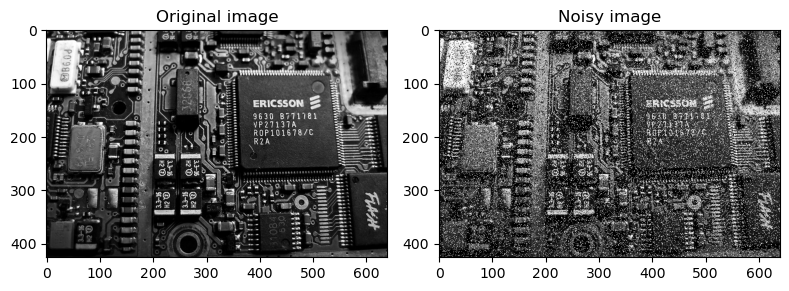

In [6]:
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(gray_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Original image')

plt.subplot(1,2,2)
plt.imshow(noisy_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Noisy image')

plt.tight_layout()

**Exercise:** Write a function `sp_noise(img, noise)` that adds salt and pepper noise to an image. Its first argument `img` should be a 2-dimensional numpy array representing the image and the second argument `noise` should be the fraction of pixels that are to be replaced by noise (for example, with `noise = 0.05` about 5% of pixels should be noise, consisting in roughly equal parts of white and black pixels). The function should return a 2-dimensional numpy array representing the original image with noise added.

## [Project 4: Image denoising](https://jllottes.github.io/Projects/image_denoising/image_denoising.html)

A description of the mean filter is provided on the [project page](https://jllottes.github.io/Projects/image_denoising/image_denoising.html). Let's try to apply the mean filter.

- For right now, we will use a `3` by `3` grid centered centered at each pixel to compute the mean.
- For right now, we will ignore all pixels at the edges of the image.

If you have a function `sp_noise` function, you should generate your own noisy image to use. For now,  I will use the hard-coded `noisy_circuit` array created above.

Again, let's make a copy `filtered_img` of the noisy array that we will filter so that we do not modify the noisy array. This way, we will be able to compare how our filtered image looks with how the noisy image looked.

In [7]:
filtered_circuit = noisy_circuit.copy()

If we are considering the pixel in the `i`th row and `j`th column (i.e. `noisy_img[i,j]`, we want a `3` by `3` slice centered on the `[i,j]`th pixel. That is, we want a slice that includes the `i-1`, `i`, and `i+1` rows and the `j-1`, `j`, and `j+1` columns.

In [8]:
i = 20
j = 50

#grid = noisy_circuit[19:22, 49:52]       # Build a 3x3 grid centered on pixel 20, 50
grid = noisy_circuit[i-1:i+2, j-1:j+2]    # Build a 3x3 grid centered on pixel i,j

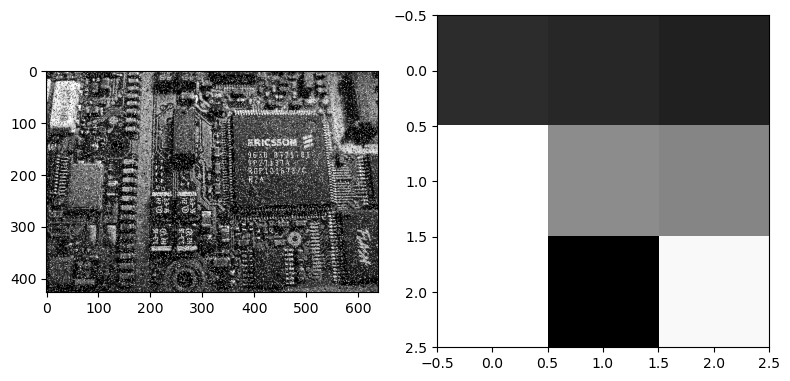

In [9]:
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(noisy_circuit, cmap='gray', vmin=0, vmax=1)

plt.subplot(1,2,2)
plt.imshow(grid, cmap='gray', vmin=0, vmax=1)

plt.tight_layout()

In [10]:
grid_mean = np.mean(grid)     # Take the mean of the 3x3 grid of pixels
print(grid_mean)

0.50021785


In [11]:
filtered_circuit[i,j] = grid_mean     # Set the i,j-th filtered pixel to the mean of the 3x3 grid

Now let's go pixel by pixel and take the mean of each `3` by `3` grid to create our filtered image array. As a reminder, for now we will ignore any problematic pixels along the edge of the image.

In [12]:
nrows, ncols = noisy_circuit.shape
filtered_circuit = noisy_circuit.copy()

In [13]:
for i in range(1,nrows-1):     # For every row other than the first and last
    for j in range(1,ncols-1): # For every column other than the first and last
        grid = noisy_circuit[i-1:i+2, j-1:j+2]     # Build a 3x3 grid centered at pixel i,j
        grid_mean = np.mean(grid)
        filtered_circuit[i,j] = grid_mean          # Set i,j-th filtered pixel to mean of the 3x3 grid

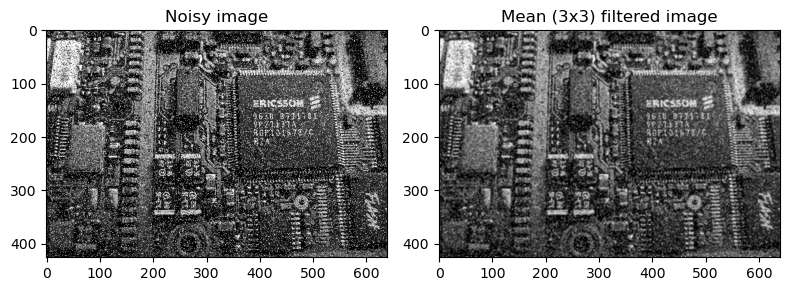

In [14]:
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(noisy_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Noisy image')

plt.subplot(1,2,2)
plt.imshow(filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Mean (3x3) filtered image')

plt.tight_layout()

What about the median filter? The `np.median` function will compute the median of an array.

In [15]:
median_filtered_circuit = noisy_circuit.copy()

In [16]:
for i in range(1,nrows-1):     # For every row other than the first and last
    for j in range(1,ncols-1): # For every column other than the first and last
        grid = noisy_circuit[i-1:i+2, j-1:j+2]     # Build a 3x3 grid centered at pixel i,j
        grid_median = np.median(grid)
        median_filtered_circuit[i,j] = grid_median # Set i,j-th filtered pixel to median of the 3x3 grid

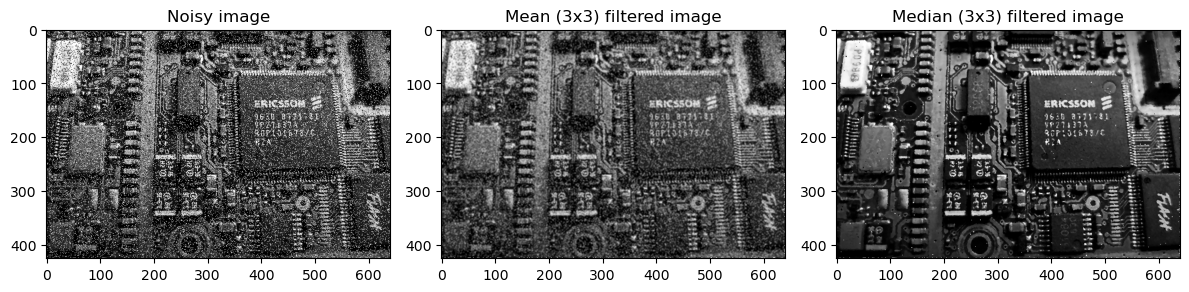

In [17]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(noisy_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Noisy image')

plt.subplot(1,3,2)
plt.imshow(filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Mean (3x3) filtered image')

plt.subplot(1,3,3)
plt.imshow(median_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Median (3x3) filtered image')

plt.tight_layout()

**Exercise:** Use the code above to write a function `simple_mean_filter` that applies the mean filter to non-edge pixels using a `3` by `3` grid.

**Exercise:** Modify the `simple_mean_filter` function to write a `simple_median_filter` that instead applies the median filter.

**Note**: We could combine these two functions into a single `simple_filter` function that takes in a noisy image array (`noisy_img`) along with some function (`filter_func`) that will be applied to each grid.

The input `filter_func` should be a Python function that takes in an 2D array and returns a float (e.g. `np.mean` or `np.median`).

In [ ]:
def simple_filter(noisy_img, filter_func):